We use pandas for analyzing the file, and we use `df.head` to understand the data, columns, and rows in the file for our analysis. 

In [1]:
import pandas as pd
df = pd.read_excel("walmart.xlsx")
df.head()

,Order ID,Order Date,Ship Date,Customer Name,Country,City,State,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,Darrin Van Huff,United States,Los Angeles,California,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,Brosina Hoffman,United States,Los Angeles,California,Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


We just use the below terms to understand the type of data stored in the file. We need to understand the data, rows, and columns in the dataset before we move on to the analysis and visualization of the particular data. It also helps to make the decision better and more precise. 

In [3]:
print("Rows and Columns:", df.shape)
df.columns
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()


Rows and Columns: (3203, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       3203 non-null   object        
 1   Order Date     3203 non-null   datetime64[ns]
 2   Ship Date      3203 non-null   datetime64[ns]
 3   Customer Name  3203 non-null   object        
 4   Country        3203 non-null   object        
 5   City           3203 non-null   object        
 6   State          3203 non-null   object        
 7   Category       3203 non-null   object        
 8   Product Name   3203 non-null   object        
 9   Sales          3203 non-null   float64       
 10  Quantity       3203 non-null   int64         
 11  Profit         3203 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int64(1), object(7)
memory usage: 300.4+ KB


np.int64(0)

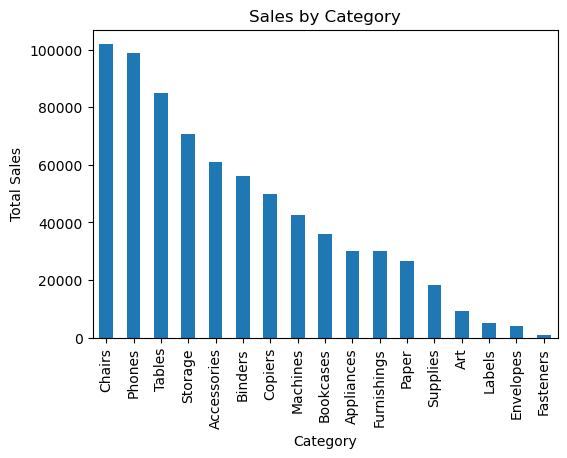

In [5]:
import matplotlib.pyplot as plt 
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

category_sales.plot(kind="bar", figsize=(6,4))

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.show()

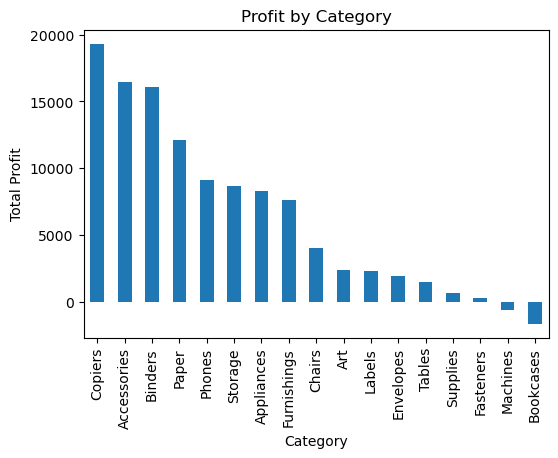

In [6]:
import matplotlib.pyplot as plt
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

category_profit.plot(kind="bar", figsize=(6,4))

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.show()

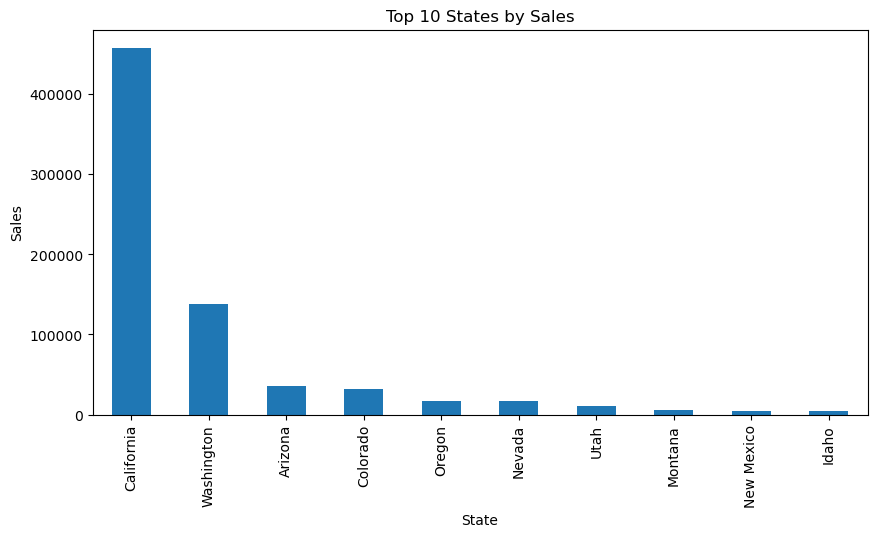

In [7]:
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10)

state_sales.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 States by Sales")
plt.xlabel("State")
plt.ylabel("Sales")

plt.show()

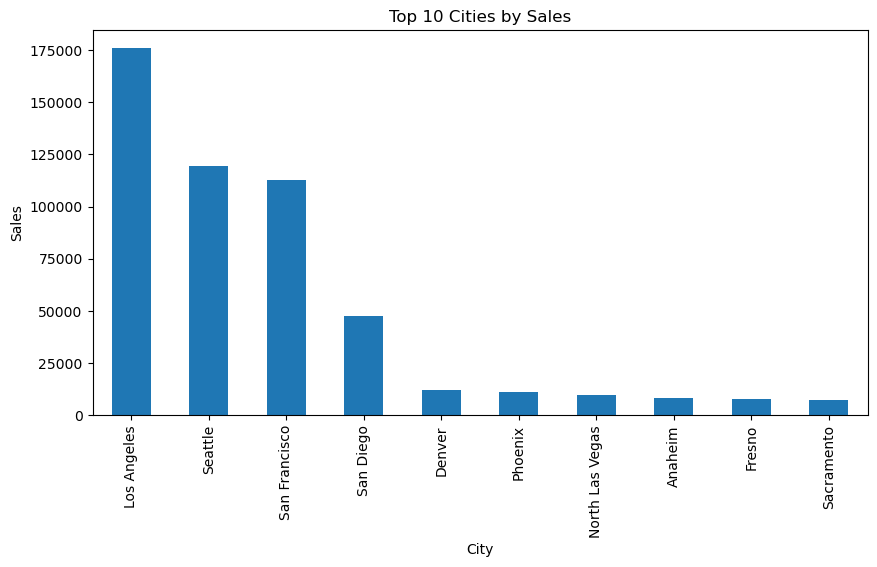

In [8]:
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False).head(10)

city_sales.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 Cities by Sales")
plt.xlabel("City")
plt.ylabel("Sales")

plt.show()

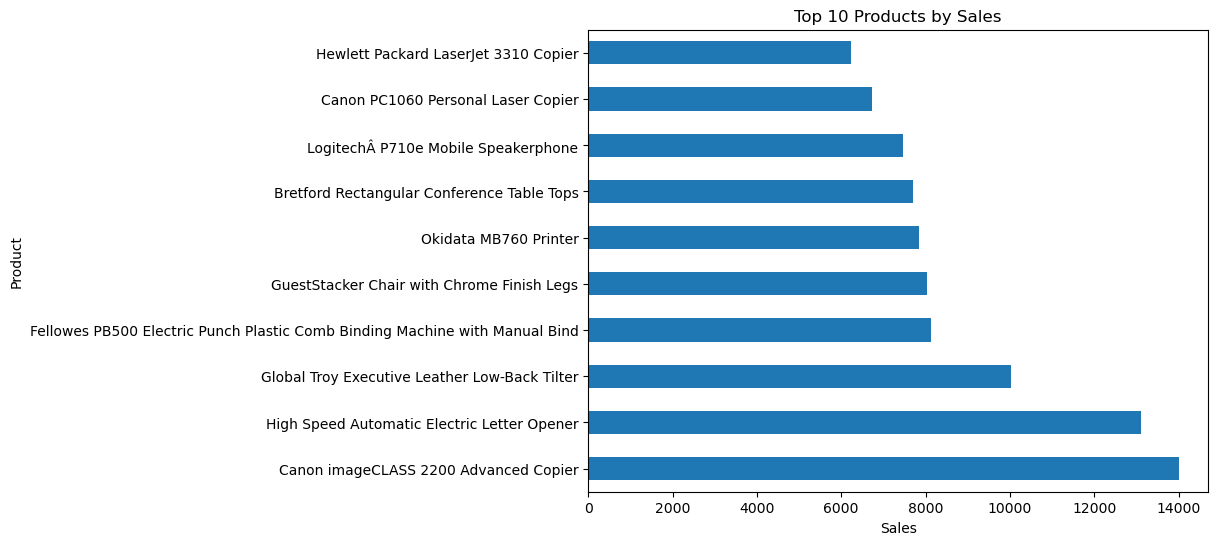

In [9]:
product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)

product_sales.plot(kind="barh", figsize=(8,6))

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")

plt.show()

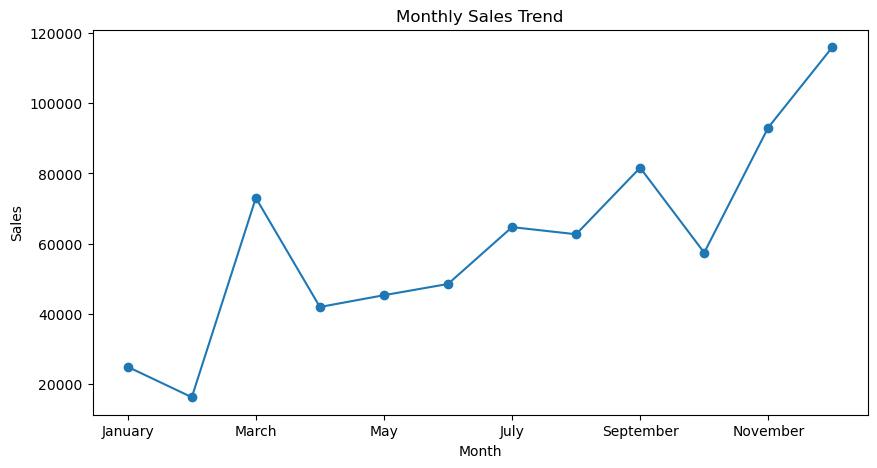

In [10]:
monthly_sales = df.groupby(df["Order Date"].dt.month_name())["Sales"].sum()

months = ["January","February","March","April","May","June",
          "July","August","September","October","November","December"]

monthly_sales = monthly_sales.reindex(months)

monthly_sales.plot(kind="line", marker="o", figsize=(10,5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.show()

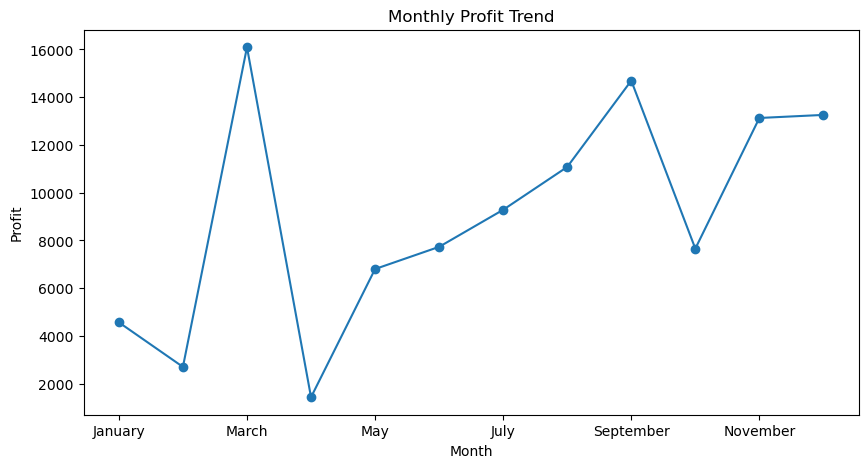

In [11]:
monthly_profit = df.groupby(df["Order Date"].dt.month_name())["Profit"].sum()

monthly_profit = monthly_profit.reindex(months)

monthly_profit.plot(kind="line", marker="o", figsize=(10,5))

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.show()

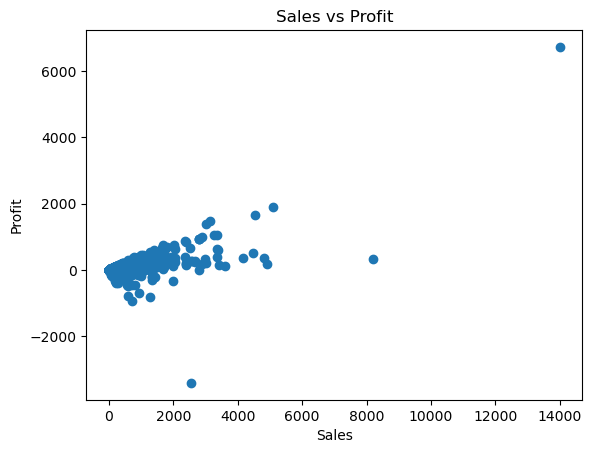

In [12]:
plt.scatter(df["Sales"], df["Profit"])

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

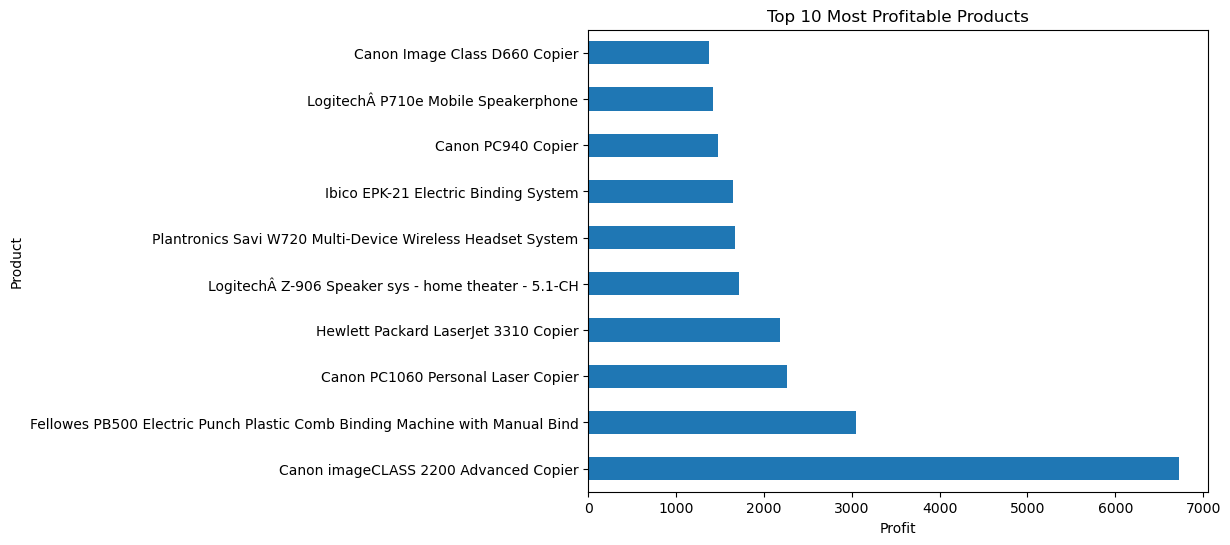

In [13]:
top_profit = (
    df.groupby("Product Name")["Profit"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_profit.plot(kind="barh", figsize=(8,6))

plt.title("Top 10 Most Profitable Products")
plt.xlabel("Profit")
plt.ylabel("Product")

plt.show()

# Business Conclusions

## Key Findings

1. Technology products generated the highest sales.
2. Some products generated high sales but comparatively low profit.
3. Certain states consistently contributed more profit than others.
4. Monthly sales showed seasonal variations.
5. The company should focus on the most profitable products instead of only the highest-selling products.
6. Top-performing cities can be prioritized for marketing campaigns.
7. Loss-making products should be reviewed for pricing and discount strategies.

## Business Recommendations

- Increase inventory for high-demand products.
- Expand business in highly profitable states.
- Improve marketing during low-sales months.
- Reduce discounts on low-profit products.
- Focus on customer retention in top-performing regions.

In [14]:
print("Number of Orders :", len(df))
print("Number of Customers :", df["Customer Name"].nunique())
print("Number of Products :", df["Product Name"].nunique())
print("Total Sales : $", round(df["Sales"].sum(),2))
print("Total Profit : $", round(df["Profit"].sum(),2))

Number of Orders : 3203
Number of Customers : 686
Number of Products : 1494
Total Sales : $ 725457.82
Total Profit : $ 108418.45


In [15]:
summary = {
    "Metric":[
        "Total Orders",
        "Unique Customers",
        "Unique Products",
        "Total Sales",
        "Total Profit"
    ],

    "Value":[
        len(df),
        df["Customer Name"].nunique(),
        df["Product Name"].nunique(),
        round(df["Sales"].sum(),2),
        round(df["Profit"].sum(),2)
    ]
}

summary_df = pd.DataFrame(summary)

summary_df

,Metric,Value
0,Total Orders,3203.00
1,Unique Customers,686.00
2,Unique Products,1494.00
3,Total Sales,725457.82
4,Total Profit,108418.45


In [16]:
summary_df.to_csv("Project_Summary.csv", index=False)